# Stroke Risk Prediction
## 1. Data Exploration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix, roc_curve, precision_recall_curve
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier


In [2]:
df = pd.read_csv("healthcare-dataset-stroke-data.csv")
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [3]:
print(df.shape)
df.info()

(5110, 12)
<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB


In [4]:
df.isna().sum()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

In [5]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


Some strange values from above for some of the columns. 
AGE: min age of 0.08, 
BMI: min bmi of 10.3 
Both of these are probably data entry issues.

In [6]:
categorical_cols = ["gender", "ever_married", "work_type", "Residence_type", "smoking_status"]
for col in categorical_cols:
    print(df[col].value_counts(dropna=False))
    print()

gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

ever_married
Yes    3353
No     1757
Name: count, dtype: int64

work_type
Private          2925
Self-employed     819
children          687
Govt_job          657
Never_worked       22
Name: count, dtype: int64

Residence_type
Urban    2596
Rural    2514
Name: count, dtype: int64

smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789
Name: count, dtype: int64



In [7]:
df.sort_values("bmi",ascending=False)[["age","bmi","stroke"]].head(10)

,age,bmi,stroke
2128,17.0,97.6,0
4209,38.0,92.0,0
928,23.0,78.0,0
544,42.0,71.9,0
1559,53.0,66.8,0
358,52.0,64.8,0
4188,27.0,64.4,0
2764,24.0,63.3,0
3825,52.0,61.6,0
2840,52.0,61.2,0


In [8]:
print(df.groupby(df["bmi"].isna())["stroke"].mean())
df.groupby(df["bmi"].isna())["stroke"].agg(["mean", "count"])


bmi
False    0.042575
True     0.199005
Name: stroke, dtype: float64


,mean,count
bmi,,
False,0.042575,4909
True,0.199005,201


In [9]:
print(df.groupby("smoking_status")["stroke"].mean())
print()
print(df.groupby("smoking_status")["age"].median())

smoking_status
Unknown            0.030440
formerly smoked    0.079096
never smoked       0.047569
smokes             0.053232
Name: stroke, dtype: float64

smoking_status
Unknown            23.0
formerly smoked    57.0
never smoked       47.0
smokes             47.0
Name: age, dtype: float64


### Data quality issues found
- bmi: 201 missing values (4%)
- somking_status: 1544 Unknown, effectively missing
- gender: 1 patient with other
- bmi: some extreme high values (max 97.6) likely errors, 
- age some infants are included in the datasets.

In [10]:
for limit in [30, 40, 50, 60, 70]:
    above = df[df["bmi"] > limit]
    strokes = above["stroke"].sum()
    count = (df["bmi"] > limit).sum()
    print(f"BMI above {limit}: {count} patients, {strokes} had a stroke")

BMI above 30: 1893 patients, 96 had a stroke
BMI above 40: 408 patients, 18 had a stroke
BMI above 50: 79 patients, 1 had a stroke
BMI above 60: 13 patients, 0 had a stroke
BMI above 70: 4 patients, 0 had a stroke


In [11]:
health_cols = ["age", "hypertension", "heart_disease", "avg_glucose_level"]
df.groupby(df["bmi"].isna())[health_cols].mean()

,age,hypertension,heart_disease,avg_glucose_level
bmi,,,,
False,42.865374,0.091872,0.049501,105.305150
True,52.049154,0.233831,0.164179,126.724627


In [12]:
print(df[df["age"] < 10]["smoking_status"].value_counts())
print()
adults = df[df["age"] >= 18 ]
print(adults.groupby("smoking_status")["stroke"].mean())

smoking_status
Unknown    472
Name: count, dtype: int64

smoking_status
Unknown            0.052204
formerly smoked    0.081395
never smoked       0.051370
smokes             0.053846
Name: stroke, dtype: float64


More Data quality discoveries:
extreme BMIs from data entry issues. 
None of the patients with a bmi of above 60 had a stroke so it might make sense to cap the bmi at that level because the people above that bmi, and maybe its a common sense judgment that that feels unlikely.

The missing-bmi patients are sicker across the board, so either it is not entered due to embarrassment. or if that is not thae case, it might be that the patients didn't get weighed and might have been having the stroke at the time, so could be a data leakage issue. 

In [13]:
#check if any of the children actually had a stroke
print(df[df["work_type"] == "children"]["stroke"].value_counts())
#check where age under 16
print(df[df["age"] < 16]["stroke"].value_counts())
#check what age the "children" patients who had a stroke were
print(df[(df["work_type"] == "children") & (df["stroke"] == 1)]["age"].value_counts())
#print all the metrics of those two children who had a stroke
print(df[(df["work_type"] == "children") & (df["stroke"] == 1)])
print(df["work_type"].value_counts())

stroke
0    685
1      2
Name: count, dtype: int64
stroke
0    742
1      2
Name: count, dtype: int64
age
1.32     1
14.00    1
Name: count, dtype: int64
        id  gender    age  hypertension  heart_disease ever_married work_type  \
162  69768  Female   1.32             0              0           No  children   
245  49669  Female  14.00             0              0           No  children   

    Residence_type  avg_glucose_level   bmi smoking_status  stroke  
162          Urban              70.37   NaN        Unknown       1  
245          Rural              57.93  30.9        Unknown       1  
work_type
Private          2925
Self-employed     819
children          687
Govt_job          657
Never_worked       22
Name: count, dtype: int64


## 2. Data Cleaning
I plan on cleaning the data in the following ways after the discoveries made in the exploratory phase.

ID column will be removed. ID is just a unique identifier label, won't have any affect on a patients likelihood of stroke

Gender where value was "Other" will be dropped from the dataset as it is 1 row in 5110 so will not have a major impact on the result of the model. Could pose problems downstream either way as "Other" could be a value that is presented in datasets in the future where the model might struggle due to not having trained on it. the model can't learn a pattern from a single example

BMI for patients with a BMI over 60, we will cap these bmis at 60. There were no strokes recorded for any of the patients with a bmi of over 60, but because we think this might be data entry error we don't want to keep the extremely high values in the dataset. But at least capping them at 60 should minimize the bmi affect on the model for these patients but still allow us to keep the data in the set to use the other metrics in each patients row.

BMI missing: we'll add a "was missing" flag column, the bmi missing is a good flag. We see a 20% stroke rate for bmi missing compared to 4.3%. we Will then fill these in with median bmi, filled with the median from the training data only to avoid data leakage.

smoking_status around 30% of the rows contain "Unknown" as the value for the smoking_status, the median age of this group is 23, so it is likely smoking wasn't recorded for the patients data because they are young. And our dataset has age in it, so it won't attribute "unknown" smoking is the reason for low stroke risk, it will have "age" as a metric to use which is probably the real reason.

Work_type = Children, I think I am going to split out work_type children from the dataset, there are only 2 of 687 where a "children" type experienced a stroke, and one of the lines has no bmi. When it gets cleaned, we would probably give this row a median from the group bmi which would be well inflated for a child of age 1.32. My plan would be to make two models, one for adults only and then one for all of the rows, and maybe see the difference.  Actually I will just use age and remove under 18s from the dataset. there are still only 2 from the 856 under 18 patients. and we are only taking out two of 249 rows with the target metric.

Children are an easy negative for the model, because only 2 of 687 had stroked. Taking out the children might lower the accuracy score from the model but will be training better on the important features. and not skewed by having many young patients who are easy "no"s to stroke risk.

In [14]:
# Check for dupes
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate ids:", df["id"].duplicated().sum())

Duplicate rows: 0
Duplicate ids: 0


In [15]:
#remove the "Other" gender category based on decision described above. to avoid issues
#with stratification because when we do that we cannot have only one row of that type
#because stratification have the same proportion of each category in the train and test sets. 
# So if we have only one row of a category, it will not be present in both the train and test sets.
df_clean = df.copy()
df_clean = df_clean[df_clean["gender"] != "Other"]
df_clean = df_clean[df_clean["age"] >= 18]## ####~~efewwedwqdwqfewkjncekvjnewjkfwefwefew

In [16]:
#add missing bmi flag
df_clean["bmi_missing"] = df_clean["bmi"].isna().astype(int)
#Check that worked
print(df_clean[["bmi_missing","bmi"]])

      bmi_missing   bmi
0               0  36.6
1               1   NaN
2               0  32.5
3               0  34.4
4               0  24.0
...           ...   ...
5105            1   NaN
5106            0  40.0
5107            0  30.6
5108            0  25.6
5109            0  26.2

[4253 rows x 2 columns]


In [17]:
#cap bmi at 60 and remove id
df_clean["bmi"] = df_clean["bmi"].clip(upper=60)
df_clean = df_clean.drop(columns=["id"])

In [18]:
#check all the cleaning worked
print(df_clean.shape)
# print(df_clean.head(10))
# print(df.shape)
print(df_clean["gender"].value_counts())
print("Max BMI:", df_clean["bmi"].max())
print("Missing BMI:", df_clean["bmi"].isna().sum())
print("Flag totals:", df_clean["bmi_missing"].sum())

(4253, 12)
gender
Female    2576
Male      1677
Name: count, dtype: int64
Max BMI: 60.0
Missing BMI: 181
Flag totals: 181


## 3. Visual Exploration

In [19]:
from matplotlib.ticker import PercentFormatter

sns.set_theme(style="whitegrid")
BAR_COLOUR = "#2a78d6"
LINE_COLOUR = "#52514E"
overall_rate = df_clean["stroke"].mean()
print(f"Overall stroke rate (adults): {overall_rate:.1%}")

Overall stroke rate (adults): 5.8%


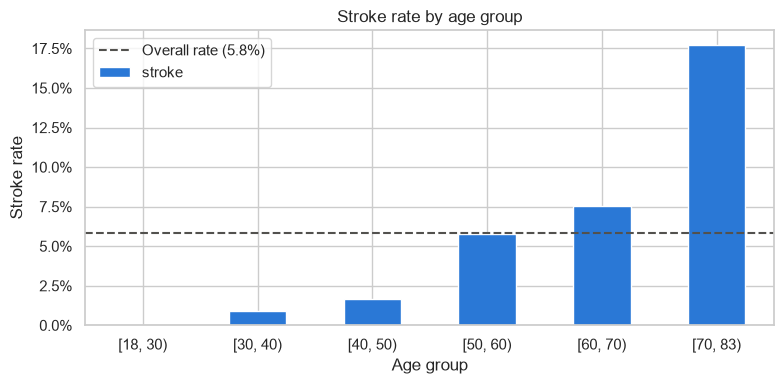

In [20]:
age_group = pd.cut(df_clean["age"], bins=[18,30,40,50,60,70,83], right=False)
age_rates = df_clean.groupby(age_group,observed=True)["stroke"].mean()

fig, ax = plt.subplots(figsize=(8,4))
age_rates.plot(kind="bar",ax=ax,color=BAR_COLOUR)
ax.axhline(overall_rate,color=LINE_COLOUR, linestyle="--",label=f"Overall rate ({overall_rate:.1%})")
ax.set_title("Stroke rate by age group")
ax.set_xlabel("Age group")
ax.set_ylabel("Stroke rate")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.tick_params(axis="x", rotation=0)
ax.legend()
plt.tight_layout()
fig.savefig("figures/stroke_by_age.png", dpi=150)
plt.show()

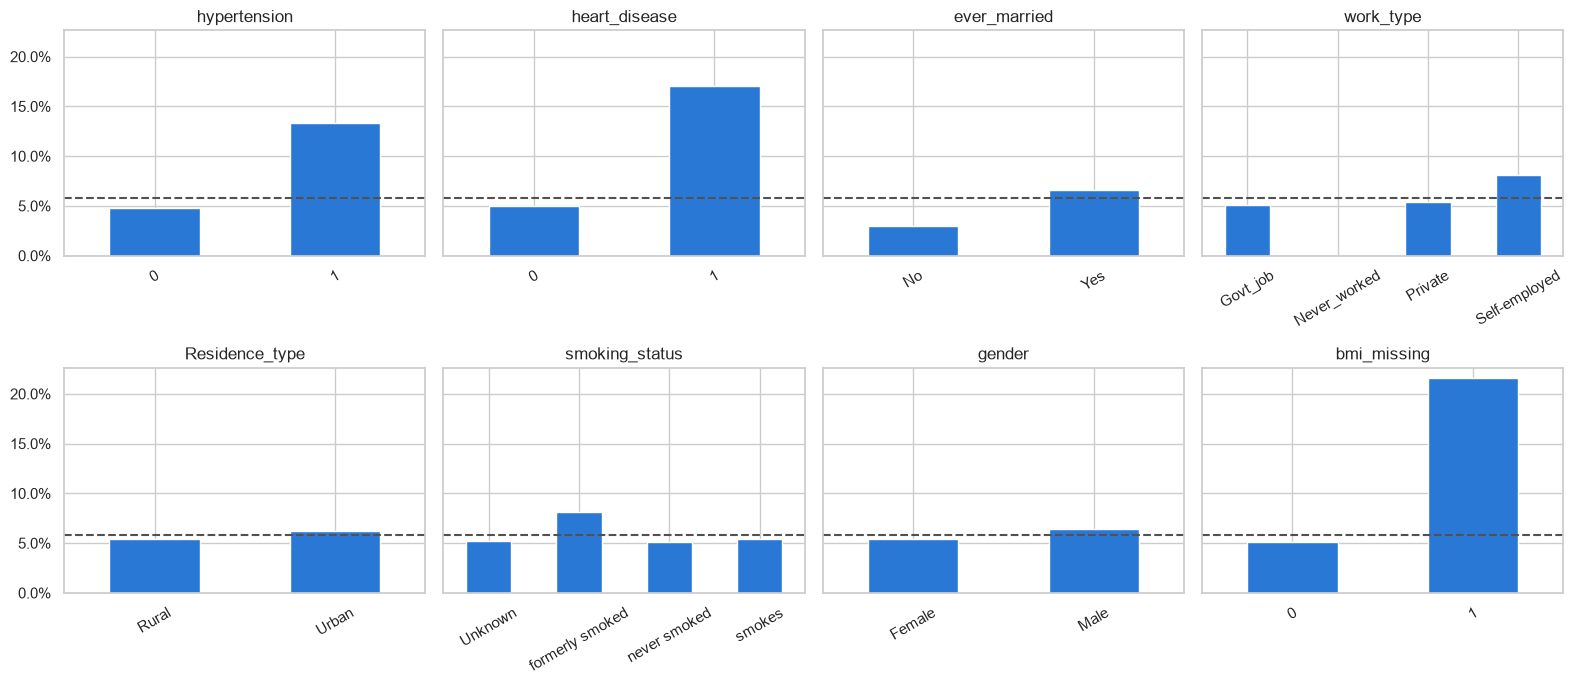

In [21]:
category_features = ["hypertension","heart_disease", "ever_married", "work_type","Residence_type","smoking_status","gender","bmi_missing"]

fig, axes = plt.subplots(2,4, figsize=(16,7), sharey=True)

for col, ax in zip(category_features, axes.flatten()):
    rates = df_clean.groupby(col)["stroke"].mean()
    rates.plot(kind="bar",ax=ax,color=BAR_COLOUR)
    ax.axhline(overall_rate, color=LINE_COLOUR,linestyle="--")
    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis="x",rotation=30)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))

plt.tight_layout()
fig.savefig("figures/stroke_by_category.png",dpi=150)
plt.show()

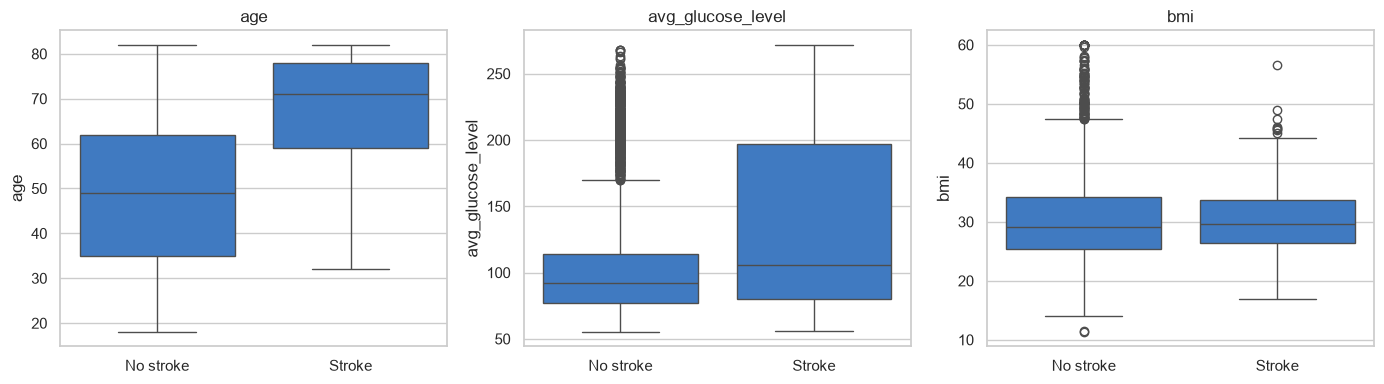

In [22]:
number_features = ["age","avg_glucose_level","bmi"]

fig, axes = plt.subplots(1,3,figsize=(14,4))

for col, ax in zip(number_features,axes):
    sns.boxplot(data=df_clean,x="stroke", y=col,ax=ax, color=BAR_COLOUR)
    ax.set_title(col)
    ax.set_xticks([0,1])
    ax.set_xticklabels(["No stroke","Stroke"])
    ax.set_xlabel("")

plt.tight_layout()
fig.savefig("figures/number_features_boxplots.png",dpi=150)
plt.show()

## 4. Baseline Model: Logistic Regression

In [23]:
# set up the table of features
X = df_clean.drop(columns=["stroke"])
# set up the target column
y = df_clean["stroke"]  
print(X.shape, y.shape)

(4253, 11) (4253,)


In [24]:
#Split into training and test sets, give it 20% of the patients, stratify it so the rate is the same in training
#and test set
X_train, X_test, y_train, y_test = train_test_split(
    X,y,test_size=0.2,stratify=y, random_state=42
)

print(f"Training:   {len(X_train)} patients, {y_train.sum()} strokes ({y_train.mean():.1%})")
print(f"Test:       {len(X_test)} patients, {y_test.sum()} strokes ({y_test.mean():.1%})")

Training:   3402 patients, 198 strokes (5.8%)
Test:       851 patients, 49 strokes (5.8%)


In [25]:

#Separate the different features into their different types
numeric_features = ["age","avg_glucose_level", "bmi"]
binary_features = ["hypertension", "heart_disease", "bmi_missing"]
categorical_features = ["gender","ever_married","work_type","Residence_type", "smoking_status"]


numeric_steps = Pipeline([
    ("impute",SimpleImputer(strategy="median")), #fills missing inputs with the median from the training data patients
    ("scale", StandardScaler()), # Put all of the three columns onto the same scale, zeroed down for the average
]) 

preprocessor = ColumnTransformer([
    ("num",numeric_steps,numeric_features),  # push the numeric features through the numeric steps pipeline mentioned above
    ("bin","passthrough", binary_features), #do no pipeline work on the numeric features
    ("cat",OneHotEncoder(handle_unknown="ignore"), categorical_features) #do one-hot encoding, separate work_types into their own binary columns. handle unkown stops the model from crashing if it sees a value never seen before.
])

In [26]:
#build the pipeline and train the model
baseline_model = Pipeline([
    ("prep",preprocessor),
    ("model",LogisticRegression(max_iter=1000))
])

baseline_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['gender','age','hypertension',...,'bmi','smoking_status','bmi_missing']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('bin', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all re

In [27]:
test_predictions = baseline_model.predict(X_test) # give the model the test set to predict off of
print("Patients predicted 'stroke' by .predict():", test_predictions.sum())
print("Actual strokes in the test set:", y_test.sum())

Patients predicted 'stroke' by .predict(): 1
Actual strokes in the test set: 49


In [28]:
#get probabilities instead as the above predicted only one stroke, because the threshold is 0.5 but the stroke 
#rate in this population is ~5% an imbalanced set.
test_probs = baseline_model.predict_proba(X_test)[:,1]

results = X_test.copy()
results["actual_stroke"] = y_test
results["predicted_prob"] = test_probs


results.sort_values("predicted_prob", ascending=False).head(15)

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,bmi_missing,actual_stroke,predicted_prob
2697,Female,73.0,1,0,Yes,Private,Rural,217.84,NaN,never smoked,1,0,0.534119
360,Female,76.0,1,0,Yes,Self-employed,Urban,209.58,NaN,never smoked,1,0,0.475036
187,Female,82.0,1,1,Yes,Govt_job,Urban,215.94,27.9,formerly smoked,0,1,0.423764
3951,Female,79.0,1,0,Yes,Self-employed,Rural,92.43,NaN,never smoked,1,0,0.419909
220,Male,81.0,1,1,Yes,Private,Urban,250.89,28.1,smokes,0,1,0.416288
2529,Female,71.0,1,0,Yes,Private,Urban,105.55,NaN,smokes,1,0,0.393441
171,Female,79.0,1,1,No,Self-employed,Rural,60.94,NaN,never smoked,1,1,0.393254
124,Female,72.0,0,0,Yes,Private,Urban,219.91,NaN,Unknown,1,1,0.377488
3162,Male,78.0,1,0,Yes,Self-employed,Urban,90.19,NaN,Unknown,1,0,0.357791
1730,Male,69.0,1,0,Yes,Private,Rural,107.11,NaN,smokes,1,0,0.350043


### 4b. Evaluating the Baseline

In [29]:
# the stroke rate we predict from the test set
base_rate = y_test.mean() 
roc_auc = roc_auc_score(y_test,test_probs)
pr_auc = average_precision_score(y_test,test_probs)

print(f"ROC AUC: {roc_auc:.3f} (random = 0.5)")
print(f"PR AUC: {pr_auc:.3f} (random = {base_rate:.3f}, the stroke rate)")

ROC AUC: 0.823 (random = 0.5)
PR AUC: 0.228 (random = 0.058, the stroke rate)


In [30]:
#try different thresholds:
for threshold in [0.05,0.10,0.20,0.30]:
    flagged = (test_probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, flagged).ravel()
    precision = tp / (tp+fp)
    recall = tp / (tp + fn)
    print(f"Threshold {threshold:.2f}: flag {flagged.sum():3d} | "
          f"TP {tp:2d} FP {fp:3d} FN {fn:2d} | "
          f"precision {precision:.0%} recall {recall:.0%}")

Threshold 0.05: flag 256 | TP 35 FP 221 FN 14 | precision 14% recall 71%
Threshold 0.10: flag 142 | TP 27 FP 115 FN 22 | precision 19% recall 55%
Threshold 0.20: flag  44 | TP 14 FP  30 FN 35 | precision 32% recall 29%
Threshold 0.30: flag  19 | TP  6 FP  13 FN 43 | precision 32% recall 12%


In [31]:
# outreach table
ranked = results.sort_values("predicted_prob", ascending=False)
total_strokes = ranked["actual_stroke"].sum()

rows = []
for n_calls in [25,50,100,150,200,300]:
    top = ranked.head(n_calls)
    reached = top["actual_stroke"].sum()
    rows.append({
        "calls": n_calls,
        "strokes_reached":reached,
        "precision": reached / n_calls,
        "recall": reached / total_strokes,
        "random_would_reach": n_calls * base_rate,
    })

outreach_table = pd.DataFrame(rows).round(2)
outreach_table

,calls,strokes_reached,precision,recall,random_would_reach
0,25,8,0.32,0.16,1.44
1,50,16,0.32,0.33,2.88
2,100,21,0.21,0.43,5.76
3,150,27,0.18,0.55,8.64
4,200,33,0.16,0.67,11.52
5,300,39,0.13,0.80,17.27


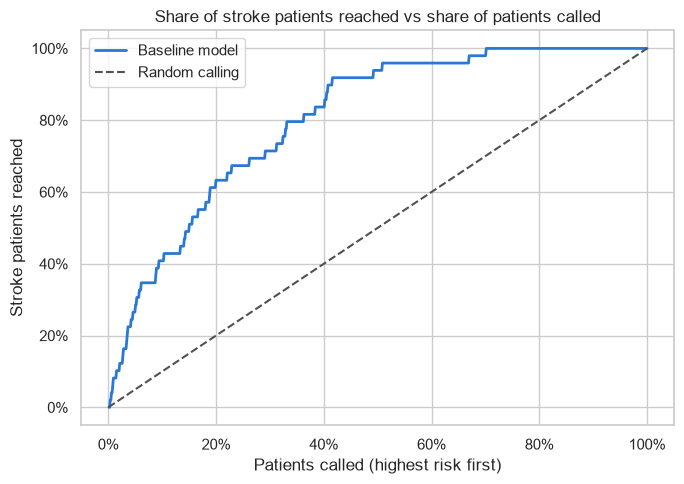

In [32]:
#cumulative gains chart
ranked["pct_called"] = np.arange(1,len(ranked) + 1) / len(ranked)
ranked["pct_strokes_reached"] = ranked["actual_stroke"].cumsum() / total_strokes

fig, ax = plt.subplots(figsize=(7,5))
ax.plot(ranked["pct_called"], ranked["pct_strokes_reached"], color=BAR_COLOUR,linewidth=2, label = "Baseline model")
ax.plot([0,1],[0,1], color=LINE_COLOUR, linestyle="--", label="Random calling")
ax.set_title("Share of stroke patients reached vs share of patients called")
ax.set_xlabel("Patients called (highest risk first)")
ax.set_ylabel("Stroke patients reached")
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.legend()
plt.tight_layout()
fig.savefig("figures/gains_baseline.png", dpi=150)
plt.show()

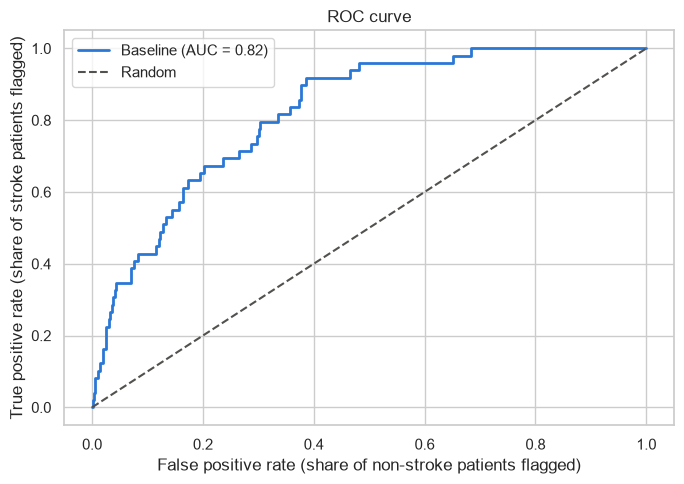

In [33]:
#ROC auc chart:
fpr, tpr, thresholds = roc_curve(y_test, test_probs)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(fpr, tpr, color=BAR_COLOUR, linewidth=2, label=f"Baseline (AUC = {roc_auc:.2f})")
ax.plot([0, 1], [0, 1], color=LINE_COLOUR, linestyle="--", label="Random")
ax.set_xlabel("False positive rate (share of non-stroke patients flagged)")
ax.set_ylabel("True positive rate (share of stroke patients flagged)")
ax.set_title("ROC curve")
ax.legend()
plt.tight_layout()
plt.show()


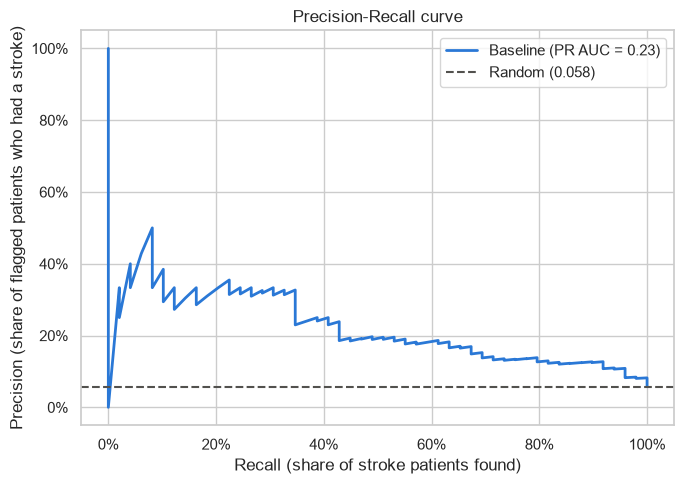

In [34]:
#precision recall curve:
precision, recall, thresholds = precision_recall_curve(y_test, test_probs)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(recall, precision, color=BAR_COLOUR, linewidth=2, label=f"Baseline (PR AUC = {pr_auc:.2f})")
ax.axhline(base_rate, color=LINE_COLOUR, linestyle="--", label=f"Random ({base_rate:.3f})")
ax.set_xlabel("Recall (share of stroke patients found)")
ax.set_ylabel("Precision (share of flagged patients who had a stroke)")
ax.set_title("Precision-Recall curve")
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.legend()
plt.tight_layout()
fig.savefig("figures/pr_curve_baseline.png", dpi=150)
plt.show()


## 5. Model Comparison

In [35]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def evaluate_model(name, model, prep=preprocessor):
    pipeline = Pipeline([("prep", prep), ("model", model)])
    scores = cross_validate(
        pipeline, X_train, y_train, cv=cv,
        scoring=["roc_auc", "average_precision"],
        return_train_score=True,
    )
    return {
        "model":name,
        "train_roc_auc": scores["train_roc_auc"].mean(),
        "cv_roc_auc": scores["test_roc_auc"].mean(),
        "cv_roc_auc_std": scores["test_roc_auc"].std(),
        "train_pr_auc": scores["train_average_precision"].mean(),
        "cv_pr_auc": scores["test_average_precision"].mean(),
        "cv_pr_auc_std": scores["test_average_precision"].std(),
    }

In [36]:
cv_results = []
cv_results.append(evaluate_model("LogisticRegression", LogisticRegression(max_iter=1000)))
pd.DataFrame(cv_results).round(3)

,model,train_roc_auc,cv_roc_auc,cv_roc_auc_std,train_pr_auc,cv_pr_auc,cv_pr_auc_std
0,LogisticRegression,0.835,0.822,0.022,0.231,0.231,0.054


In [37]:
#a random forest with default settings
cv_results.append(evaluate_model("Random fores (default)", RandomForestClassifier(random_state=42)))
pd.DataFrame(cv_results).round(3)

,model,train_roc_auc,cv_roc_auc,cv_roc_auc_std,train_pr_auc,cv_pr_auc,cv_pr_auc_std
0,LogisticRegression,0.835,0.822,0.022,0.231,0.231,0.054
1,Random fores (default),1.000,0.772,0.029,1.000,0.189,0.022


In [38]:
cv_results.append(evaluate_model(
    "Random forest (min 20 per leaf)",
    RandomForestClassifier(n_estimators=500, min_samples_leaf=20, random_state=42),
))
pd.DataFrame(cv_results).round(3)

,model,train_roc_auc,cv_roc_auc,cv_roc_auc_std,train_pr_auc,cv_pr_auc,cv_pr_auc_std
0,LogisticRegression,0.835,0.822,0.022,0.231,0.231,0.054
1,Random fores (default),1.000,0.772,0.029,1.000,0.189,0.022
2,Random forest (min 20 per leaf),0.909,0.810,0.026,0.421,0.215,0.040


In [39]:
#gradient boosting with default settings
cv_results.append(evaluate_model("Gradient boosting (default)", GradientBoostingClassifier(random_state=42)))
pd.DataFrame(cv_results).round(3)

,model,train_roc_auc,cv_roc_auc,cv_roc_auc_std,train_pr_auc,cv_pr_auc,cv_pr_auc_std
0,LogisticRegression,0.835,0.822,0.022,0.231,0.231,0.054
1,Random fores (default),1.000,0.772,0.029,1.000,0.189,0.022
2,Random forest (min 20 per leaf),0.909,0.810,0.026,0.421,0.215,0.040
3,Gradient boosting (default),0.945,0.806,0.026,0.719,0.232,0.048


In [40]:
preprocessor_no_flag = ColumnTransformer([
    ("num", numeric_steps, numeric_features),
    ("bin", "passthrough", ["hypertension", "heart_disease"]),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])

cv_results.append(evaluate_model("Logistic regression (no bmi_missing)",
                                 LogisticRegression(max_iter=1000), prep=preprocessor_no_flag))
pd.DataFrame(cv_results).round(3)


,model,train_roc_auc,cv_roc_auc,cv_roc_auc_std,train_pr_auc,cv_pr_auc,cv_pr_auc_std
0,LogisticRegression,0.835,0.822,0.022,0.231,0.231,0.054
1,Random fores (default),1.000,0.772,0.029,1.000,0.189,0.022
2,Random forest (min 20 per leaf),0.909,0.810,0.026,0.421,0.215,0.040
3,Gradient boosting (default),0.945,0.806,0.026,0.719,0.232,0.048
4,Logistic regression (no bmi_missing),0.824,0.813,0.016,0.200,0.201,0.030


# Model Decision

Logistic regression seems to be a very viable model option. The random forest default and small 20 per leaf adjustment, as well as gradient boosting didn't perform well enough to warrant using a more complicated model. Also removing the bmi missing flag reduced performance minimally, so the model does not rely too much on it. 

## Decisions: Who to call and what to expect

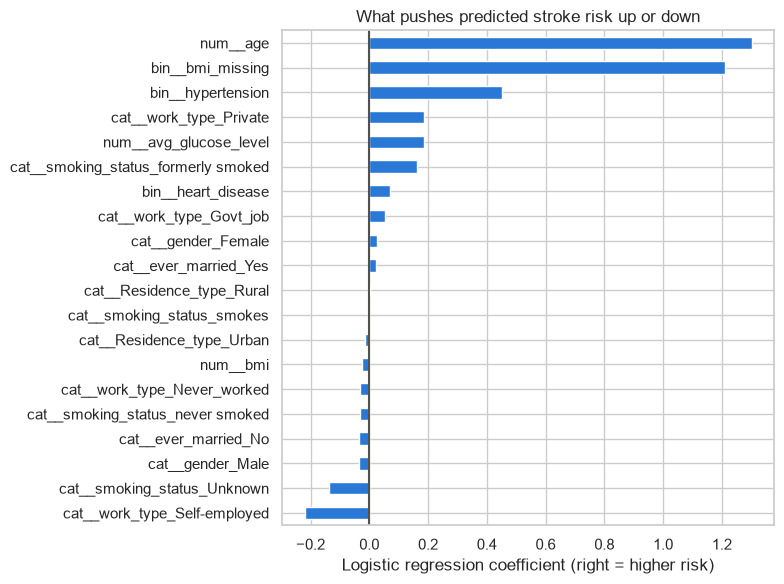

In [41]:
feature_names = baseline_model.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(baseline_model.named_steps["model"].coef_[0], index=feature_names).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
coefs.plot(kind="barh", ax=ax, color=BAR_COLOUR)
ax.axvline(0, color=LINE_COLOUR)
ax.set_title("What pushes predicted stroke risk up or down")
ax.set_xlabel("Logistic regression coefficient (right = higher risk)")
plt.tight_layout()
fig.savefig("figures/coefficients.png", dpi=150)
plt.show()


In [42]:
rows = []
for pct in [0.05, 0.10, 0.15, 0.20, 0.30]:
    n_calls = round(pct * len(ranked))
    top = ranked.head(n_calls)
    reached = top["actual_stroke"].sum()
    rows.append({
        "top_pct": pct,
        "calls": n_calls,
        "strokes_reached": reached,
        "recall": reached / total_strokes,
        "precision": reached / n_calls,
        "lift": (reached / n_calls) / base_rate,
        "threshold": top["predicted_prob"].min(),
    })

pct_table = pd.DataFrame(rows).round(3)
pct_table


,top_pct,calls,strokes_reached,recall,precision,lift,threshold
0,0.05,43,14,0.286,0.326,5.654,0.204
1,0.10,85,20,0.408,0.235,4.086,0.149
2,0.15,128,25,0.510,0.195,3.392,0.112
3,0.20,170,31,0.633,0.182,3.167,0.087
4,0.30,255,35,0.714,0.137,2.384,0.050
